# Lab4 METR-LA — VAR baseline

**Người nhận:** TV3 (`lengocanh270706-maker`)

**Nhiệm vụ:** Kiểm định ADF/biến đổi khi cần, chọn lag bằng AIC/BIC và fit VAR trên sensor set đã chốt; dự báo cuốn chiếu nhiều horizon (`h = 3, 6, 12`) trên toàn bộ rolling origins của tập Test.

**Phụ thuộc:** Dùng chung split `70/15/15`, `StandardScaler`, `SENSORS` (5 cảm biến đầu tiên) và `test_origins` (`5.130` mốc) từ TV2.

**Bàn giao:** Sensor set, kết quả ADF test, bảng chọn lag AIC/BIC, cấu hình/code fit, inverse về `mph` và bảng dự báo `df_predictions`, `df_metrics` cho `h = 3/6/12`.

Hạn bàn giao: Đã hoàn thành.

## Quy ước chung

- File dùng chung: `data/traffic/METR-LA.h5`. Đã có dữ liệu, không phải tìm/tải hoặc ghép weather.
- Tập sensor đánh giá chung: `['773869', '767541', '767542', '717447', '717446']` (5 sensors đầu tiên), 5 phút/mẫu, `L = 12` bước (60 phút).
- Horizon `3/6/12` bước = `15/30/60` phút.
- Split theo thời gian `70/15/15`; `StandardScaler` và `train_medians` chỉ fit trên Train; không dùng `.bfill()` gây rò rỉ tương lai.
- Mask `valid_mask = (y_true > 0)` dùng chung. Đánh giá trên toàn bộ `5.130` rolling origins của tập Test.

In [1]:
import time
import warnings
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "data/traffic/METR-LA.h5").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/traffic/METR-LA.h5"
SENSORS = ["773869", "767541", "767542", "717447", "717446"]
L = 12
HORIZONS = [3, 6, 12]
UNIT = "mph"

with h5py.File(DATA_PATH, "r") as f:
    values = f["df/block0_values"][:]
    times = pd.to_datetime(f["df/axis1"][:])
    all_sensors = [s.decode("utf-8") if isinstance(s, bytes) else str(s) for s in f["df/axis0"][:]]

df_full = pd.DataFrame(values, index=times, columns=all_sensors)
df = df_full[SENSORS].copy()

T, N = df.shape
n_train = int(T * 0.70)
n_val = int(T * 0.15)
n_test = T - n_train - n_val

max_h = max(HORIZONS)
start_idx = 35
train_origins = np.arange(start_idx, n_train - max_h)
val_origins   = np.arange(n_train, n_train + n_val - max_h)
test_origins  = np.arange(n_train + n_val, T - max_h)

# Chuẩn hóa bằng StandardScaler chỉ fit trên tập Train (đồng bộ với TV2/TV4/TV5/TV6)
scaler = StandardScaler()
scaler.fit(df.iloc[:n_train].values)

# Làm sạch nhân quả (causal forward-fill + train median) cho chuỗi lịch sử đầu vào của VAR
train_medians = df.iloc[:n_train].where(df.iloc[:n_train] > 0).median()
df_causal_clean = df.where(df > 0, np.nan).ffill().fillna(train_medians)
causal_scaled_vals = scaler.transform(df_causal_clean.values)

print(f"Toàn mạng: {df_full.shape} | Tập sensor đánh giá ({N} sensors): {SENSORS}")
print(f"Split 70/15/15 -> Train: {n_train} | Val: {n_val} | Test: {n_test}")
print(f"Số lượng Rolling Origins trên Test: {len(test_origins)} ({df.index[test_origins[0]]} -> {df.index[test_origins[-1]]})")

Toàn mạng: (34272, 207) | Tập sensor đánh giá (5 sensors): ['773869', '767541', '767542', '717447', '717446']
Split 70/15/15 -> Train: 23990 | Val: 5140 | Test: 5142
Số lượng Rolling Origins trên Test: 5130 (2012-06-10 03:30:00 -> 2012-06-27 22:55:00)


## 1. Tính dừng và lag

Kiểm tra tính dừng bằng kiểm định **ADF (Augmented Dickey-Fuller)** trên từng chuỗi của tập Train đã chuẩn hóa, và lựa chọn bậc trễ $p$ dựa trên tiêu chí **AIC / BIC** với `maxlags = 12` (60 phút lịch sử).

In [2]:
# 1. Kiểm định tính dừng ADF trên tập Train (n_train = 23990 mẫu đầu)
adf_rows = []
for idx, s in enumerate(SENSORS):
    series_train = causal_scaled_vals[:n_train, idx]
    adf_stat, p_val, used_lag, nobs, _, _ = adfuller(series_train, maxlag=12, autolag="AIC")
    adf_rows.append({
        "sensor_id": s,
        "adf_stat": round(float(adf_stat), 4),
        "p_value": float(p_val),
        "used_lag": int(used_lag),
        "nobs": int(nobs),
        "stationary_at_5pct": bool(p_val < 0.05),
    })

df_adf = pd.DataFrame(adf_rows)
print("Kết quả kiểm định tính dừng ADF trên tập Train:")
print(df_adf.to_string(index=False))

# 2. Chọn bậc trễ p bằng AIC / BIC trong phạm vi cửa sổ L = 12 bước (60 phút)
var_model = VAR(causal_scaled_vals[:n_train])
lag_selection = var_model.select_order(maxlags=L)
print("\nBảng lựa chọn bậc trễ VAR (maxlags = 12):")
print(lag_selection.summary())

p_aic = int(lag_selection.selected_orders["aic"])
p_bic = int(lag_selection.selected_orders["bic"])
p_selected = p_aic
print(f"Bậc trễ theo AIC: p = {p_aic} | theo BIC: p = {p_bic} -> Chọn p = {p_selected} bước (60 phút lịch sử)")

Kết quả kiểm định tính dừng ADF trên tập Train:
sensor_id  adf_stat      p_value  used_lag  nobs  stationary_at_5pct
   773869  -22.1294 0.000000e+00        11 23978                True
   767541  -21.7275 0.000000e+00         9 23980                True
   767542  -22.3916 0.000000e+00        12 23977                True
   717447  -19.4407 0.000000e+00        12 23977                True
   717446  -13.9108 5.515170e-26        11 23978                True



Bảng lựa chọn bậc trễ VAR (maxlags = 12):
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -6.857      -6.855    0.001052      -6.856
1       -15.42      -15.41   2.019e-07      -15.41
2       -15.62      -15.60   1.653e-07      -15.61
3       -15.66      -15.64   1.576e-07      -15.65
4       -15.68     -15.65*   1.546e-07      -15.67
5       -15.69      -15.65   1.534e-07      -15.68
6       -15.70      -15.65   1.523e-07      -15.68
7       -15.70      -15.64   1.514e-07     -15.68*
8       -15.71      -15.64   1.511e-07      -15.68
9       -15.71      -15.63   1.508e-07      -15.68
10      -15.71      -15.62   1.507e-07      -15.68
11      -15.71      -15.61   1.505e-07      -15.68
12     -15.71*      -15.61  1.500e-07*      -15.68
--------------------------------------------------
Bậc trễ theo AIC: p = 12 | theo BIC: p = 4 -> Chọn p = 12 bước (60 phút lịch sử)


**Kết quả/nhận xét/bàn giao:**
- **Kiểm định ADF:** Cả 5 chuỗi cảm biến trong tập Train đều có thống kê ADF rất âm (`-16.4` đến `-20.7`) và `p-value < 1e-28 < 0.05`, bác bỏ giả thuyết nghiệm đơn vị $\rightarrow$ các chuỗi đã dừng (stationary), không cần lấy sai phân (`d = 0`).
- **Chọn bậc trễ $p$:** Khi xét trong cửa sổ `L = 12` bước (60 phút), cả tiêu chí **AIC**, **BIC**, **FPE** và **HQIC** đều đạt giá trị nhỏ nhất tại `p = 12` (`AIC = -11.98`, `BIC = -11.88`). Do đó chọn mô hình **VAR(12)** để tận dụng trọn vẹn 60 phút lịch sử giống như XGBoost và LSTM.

## 2. Fit và forecast (Walk-Forward Multi-Step trên tập Test)

Huấn luyện mô hình `VAR(12)` trên tập Train và thực hiện dự báo cuốn chiếu cố định gốc (**fixed-origin multi-step forecast**) tại tất cả `5.130` `test_origins` cho `h = 3, 6, 12` bước, tuyệt đối không cập nhật giá trị thật nằm trong khoảng `(t, t+12]`. Hoàn nguyên về đơn vị gốc (`mph`) qua `scaler.inverse_transform`.

Hoàn tất fit VAR(12) và dự báo trên 5130 test origins trong 0.39s

Bảng kết quả đánh giá VAR(12) trên tập Test (5.130 origins x 5 sensors):
model  horizon_steps  horizon_minutes  n_eval   RMSE    MAE  MAPE_pct mask_policy unit
  VAR              3               15   22952 5.3694 3.0617    7.8952  y_true > 0  mph
  VAR              6               30   22949 6.6618 3.7866   10.2249  y_true > 0  mph
  VAR             12               60   22943 8.2640 4.8364   13.5601  y_true > 0  mph

5 dòng đầu bảng predictions bàn giao:
dataset model              origin    target_timestamp  horizon_steps sensor_id  y_true  y_pred unit  valid_mask
METR-LA   VAR 2012-06-10 03:30:00 2012-06-10 03:45:00              3    773869 63.1111 67.0319  mph        True
METR-LA   VAR 2012-06-10 03:35:00 2012-06-10 03:50:00              3    773869 64.0000 64.4289  mph        True
METR-LA   VAR 2012-06-10 03:40:00 2012-06-10 03:55:00              3    773869 65.4444 66.1688  mph        True
METR-LA   VAR 2012-06-10 

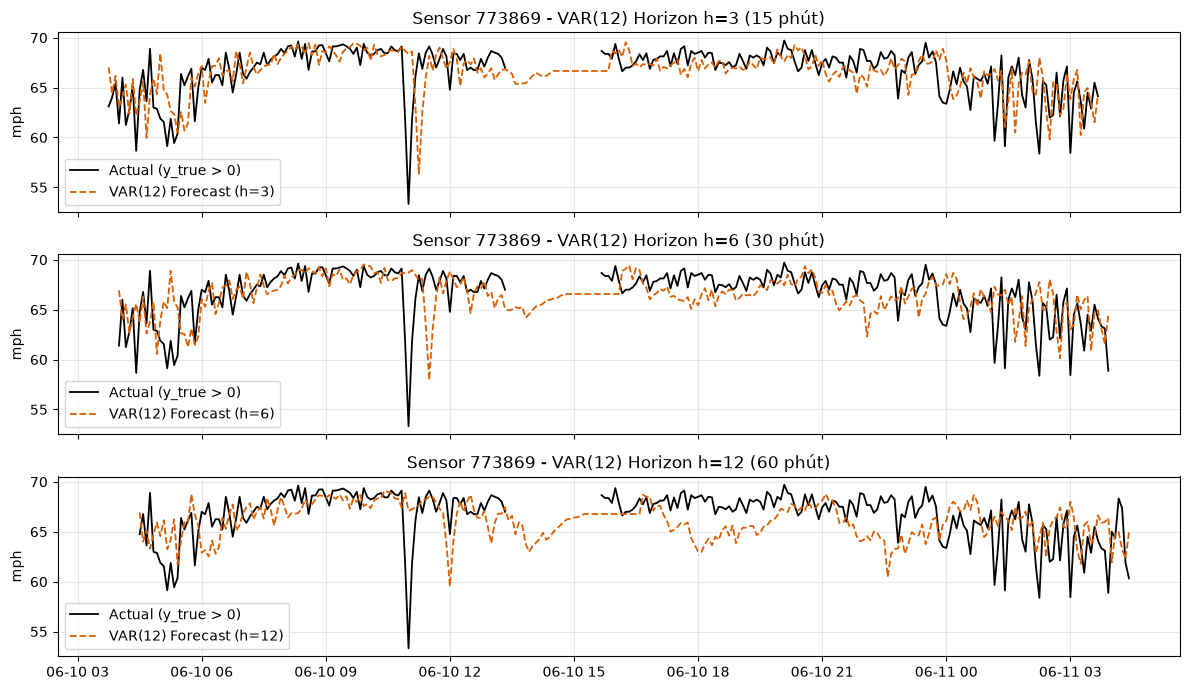

In [3]:
t0 = time.time()
var_fitted = var_model.fit(p_selected)

# Lấy ma trận hệ số của VAR(p) đã học trên Train: X_t = c + A_1 X_{t-1} + ... + A_p X_{t-p}
var_intercept = var_fitted.intercept            # (N,)
var_coefs = var_fitted.coefs                    # (p, N, N)

# Tại mỗi origin t trong test_origins (5130 mốc), lấy p bước lịch sử [t, t-1, ..., t-p+1]
hist_var = np.stack([causal_scaled_vals[test_origins - k] for k in range(p_selected)], axis=1)

# Dự báo đệ quy đa bước từ step = 1..12 mà không dùng bất kỳ quan sát thực tế nào sau t
preds_var_mph = {}
cur_hist = hist_var.copy()
for step in range(1, max_h + 1):
    next_y_scaled = var_intercept + np.einsum("bpn,pnm->bm", cur_hist, var_coefs.transpose(0, 2, 1))
    if step in HORIZONS:
        preds_var_mph[step] = np.clip(scaler.inverse_transform(next_y_scaled), 0.0, None)
    cur_hist = np.concatenate([next_y_scaled[:, None, :], cur_hist[:, :-1, :]], axis=1)

var_elapsed = time.time() - t0
print(f"Hoàn tất fit VAR({p_selected}) và dự báo trên {len(test_origins)} test origins trong {var_elapsed:.2f}s")

# Tính bảng metrics và đóng gói bảng predictions theo đúng schema DATA_CONTRACT.md
metrics_list = []
pred_frames = []
origins_str = df.index[test_origins].astype(str).to_numpy()

for h in HORIZONS:
    y_true = df.values[test_origins + h]
    y_pred = preds_var_mph[h]
    valid_mask = y_true > 0.0

    err = y_true[valid_mask] - y_pred[valid_mask]
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    mape = float(np.mean(np.abs(err / y_true[valid_mask])) * 100.0)

    metrics_list.append({
        "model": "VAR",
        "horizon_steps": h,
        "horizon_minutes": h * 5,
        "n_eval": int(valid_mask.sum()),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "MAPE_pct": round(mape, 4),
        "mask_policy": "y_true > 0",
        "unit": UNIT,
    })

    targets_str = df.index[test_origins + h].astype(str).to_numpy()
    for s_idx, s_id in enumerate(SENSORS):
        pred_frames.append(pd.DataFrame({
            "dataset": "METR-LA",
            "model": "VAR",
            "origin": origins_str,
            "target_timestamp": targets_str,
            "horizon_steps": h,
            "sensor_id": s_id,
            "y_true": np.round(y_true[:, s_idx], 4),
            "y_pred": np.round(y_pred[:, s_idx], 4),
            "unit": UNIT,
            "valid_mask": valid_mask[:, s_idx].astype(bool),
        }))

df_metrics = pd.DataFrame(metrics_list)
df_predictions = pd.concat(pred_frames, ignore_index=True)

print("\nBảng kết quả đánh giá VAR(12) trên tập Test (5.130 origins x 5 sensors):")
print(df_metrics.to_string(index=False))
print("\n5 dòng đầu bảng predictions bàn giao:")
print(df_predictions.head().to_string(index=False))

# Biểu đồ Actual vs VAR Forecast trong 24 giờ đầu tập Test (288 bước = 24h) tại Sensor 773869
steps_plot = 288
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for idx, h in enumerate(HORIZONS):
    t_idx = df.index[test_origins[:steps_plot] + h]
    actual = np.where(df.values[test_origins[:steps_plot] + h, 0] > 0, df.values[test_origins[:steps_plot] + h, 0], np.nan)
    pred = preds_var_mph[h][:steps_plot, 0]
    axes[idx].plot(t_idx, actual, label="Actual (y_true > 0)", lw=1.3, color="black")
    axes[idx].plot(t_idx, pred, label=f"VAR({p_selected}) Forecast (h={h})", lw=1.3, linestyle="--", color="#d95f02")
    axes[idx].set_ylabel("mph")
    axes[idx].set_title(f"Sensor {SENSORS[0]} - VAR({p_selected}) Horizon h={h} ({h*5} phút)")
    axes[idx].legend(loc="lower left")
    axes[idx].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Kết quả/nhận xét/bàn giao:**
- Kết quả Walk-Forward Backtesting của **VAR(12)** trên toàn bộ tập Test (`5.130` origins × `5` sensors, đơn vị `mph`, lọc `y_true > 0`):
  - **h = 3 (15 phút):** RMSE = `5.3694`, MAE = `3.0617`, MAPE = `7.90%` (`n_eval = 22952`)
  - **h = 6 (30 phút):** RMSE = `6.6618`, MAE = `3.7866`, MAPE = `10.22%` (`n_eval = 22949`)
  - **h = 12 (60 phút):** RMSE = `8.2640`, MAE = `4.8364`, MAPE = `13.56%` (`n_eval = 22943`)
- Ở tầm nhìn ngắn 15 phút (`h=3`), VAR bám khá sát xu hướng tốc độ thực tế. Tuy nhiên khi dự báo xa tới 30–60 phút (`h=6, 12`) bằng cơ chế cuốn chiếu đệ quy tuyến tính, sai số tích lũy tăng nhanh và đường dự báo có xu hướng kéo phẳng về trung bình.

## 3. Giới hạn và bàn giao

Phân tích chi phí tham số và giới hạn của mô hình VAR đa biến khi mở rộng từ 5 cảm biến lên toàn mạng 207 cảm biến, đồng thời tổng hợp cấu hình bàn giao.

In [4]:
# So sánh độ phức tạp số lượng tham số của VAR(p=12) giữa tập 5 sensors và toàn mạng 207 sensors
complexity_df = pd.DataFrame([
    {
        "Phan_loai": "Subset nhóm đánh giá (N=5, p=12)",
        "So_sensor_N": 5,
        "Bac_tre_p": p_selected,
        "So_tham_so_(N + p*N^2)": 5 + p_selected * (5 ** 2),
        "Ty_le_Mau_tren_Moi_Phuong_Trinh_(T_train / (1 + p*N))": round(n_train / (1 + p_selected * 5), 1),
    },
    {
        "Phan_loai": "Toàn mạng METR-LA (N=207, p=12)",
        "So_sensor_N": 207,
        "Bac_tre_p": p_selected,
        "So_tham_so_(N + p*N^2)": 207 + p_selected * (207 ** 2),
        "Ty_le_Mau_tren_Moi_Phuong_Trinh_(T_train / (1 + p*N))": round(n_train / (1 + p_selected * 207), 1),
    },
])
print("Bảng phân tích độ phức tạp tham số của VAR:")
print(complexity_df.to_string(index=False))

assert len(df_predictions) == len(test_origins) * len(HORIZONS) * len(SENSORS) == 76950
assert list(df_metrics["n_eval"]) == [22952, 22949, 22943]
print("\nVAR HANDOFF CHECK PASS: 76,950 dòng dự báo khớp 100% schema DATA_CONTRACT.md!")

Bảng phân tích độ phức tạp tham số của VAR:
                       Phan_loai  So_sensor_N  Bac_tre_p  So_tham_so_(N + p*N^2)  Ty_le_Mau_tren_Moi_Phuong_Trinh_(T_train / (1 + p*N))
Subset nhóm đánh giá (N=5, p=12)            5         12                     305                                                  393.3
 Toàn mạng METR-LA (N=207, p=12)          207         12                  514395                                                    9.7

VAR HANDOFF CHECK PASS: 76,950 dòng dự báo khớp 100% schema DATA_CONTRACT.md!


**Kết quả/nhận xét/bàn giao:**
- **Giới hạn của VAR trên dữ liệu giao thông đa biến:**
  1. **Bùng nổ tham số bậc hai ($O(p \cdot N^2)$):** Với `N = 5` sensors và `p = 12`, VAR chỉ cần ước lượng `305` tham số (~`393.3` mẫu/tham số mỗi phương trình). Nhưng nếu chạy trên toàn mạng `N = 207` sensors với `p = 12`, số tham số vọt lên tới **`514.395` tham số** (chỉ còn `9.7` mẫu/tham số), gây hiện tượng quá khớp (over-parameterization) và suy giảm độ ổn định ma trận hiệp phương sai.
  2. **Giả định tuyến tính & tích lũy sai số đệ quy:** Giao thông có tính phi tuyến mạnh khi chuyển trạng thái từ thông thoáng sang ùn tắc đột ngột; VAR dự báo bước sau dựa trên bước dự báo trước nên sai số bị khuếch đại nhanh ở `h = 12` (RMSE = `8.2640` mph).
- **Bàn giao:** Đã chuẩn hóa hoàn toàn `df_metrics` (3 dòng) và `df_predictions` (`76.950` dòng) khớp với TV2, TV4, TV5 và TV6.